# Definicja danych wejściowych i wyjściowych
Projekt opiera się na danych z konkursu **KiTS23** -- https://kits-challenge.org/kits23/

Konkurs opierał się na porównywaniu skuteczności modeli segmentujących skany medyczne osób z nowotworami nerek. Modele z konkursu były trenowane do rozpoznawania 3 obiektów: nerki, guzy i cysty.

W moim projekcie jako dane wejściowe będziemy wykorzystywać dane wyjściowe z tego projektu -- segmentacje. Mój model, na podstawie tych segmentacji będzie klasyfikował pojedyncze nowotwory (przypadki z wieloma nowotworami lub cystami zostały odrzucone z puli danych) na podstawie skali **RPN** (https://pmc.ncbi.nlm.nih.gov/articles/PMC10397239/), wykorzystywaną do oceny trudności operacyjnego usunięcia guza.

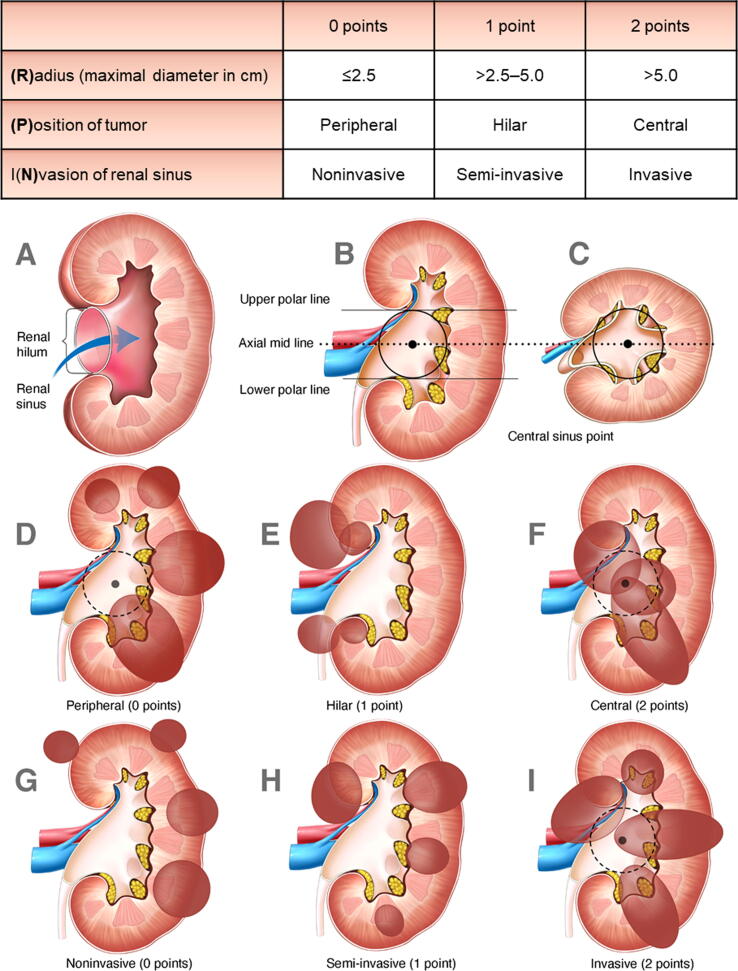

Jako że guzy w zbiorze danych KiTS23 nie zostały podane z ocenami w tej skali, ich ocenę wykonają lekarze medycyny, specjalizujący się w nowotworach nerek, z którymi współpracuję przy tym projekcie.

# Lokalizacja danych
Dane z KiTS23 można pobrać postępując zgodnie z instrukcją w repo projektu -- https://github.com/neheller/kits23.

*Annotacja / Dane wyjściowe* projektu są zapisywane ręcznie przez lekarzy medycznych w przygotowanym przeze mnie arkuszu Google Sheets.

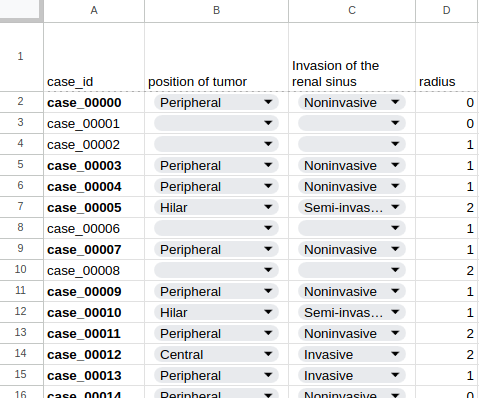

# Przewidywana architektura modelu
Model będzie się składał z dwóch podmodeli:
1. Konwolucyjnej sieci neuronowej z 6 neuronami wyjściowymi 

(position of tumor, Invasion of renal sinus -- do obu cech pasują 3 możliwe opcje, więc wykorzystując one-hot encoding mamy 2 * 3 = 6 neuronów na wyjściu)

2. Numeryczny model liczący najdłuższą linię w nowotworze "średnicę", następnie wykorzystując zasady skali RPN tłumaczy tę wartość na 0, 1 lub 3 punkty